# Movie Review Sentiment, Part 2: Training Custom Classifiers

**Question:** can a model trained on labeled movie reviews beat the prebuilt analyzers from Part 1 (TextBlob 68.5%, VADER 69.4%)?

**Data:** the same 25,000 labeled IMDB movie reviews, half positive and half negative.

**Approach:**
1. Clean the text: lowercase, remove punctuation, remove stop words, stem each word (PorterStemmer)
2. Build bag-of-words and TF-IDF matrices (92,226 distinct stemmed words)
3. Split 80/20 into training and test sets; fit TF-IDF on the training reviews only to avoid data leakage
4. Train logistic regression and multinomial Naive Bayes, then compare them on the 5,000 test reviews

**Key results:**
- Logistic regression: 89.1% accuracy, F1 0.892, ROC AUC 0.958
- Naive Bayes: 87.5% accuracy, F1 0.874, ROC AUC 0.945
- Both beat the prebuilt analyzers by 18 to 21 percentage points
- The words that drive predictions make intuitive sense: "worst", "waste" and "bad" push toward negative; "great", "excellent" and "best" push toward positive

**Tools:** Python (pandas, NLTK, scikit-learn, matplotlib)

**Context:** master's coursework (DSC550, Weeks 3 and 5), cleaned up and corrected for this portfolio. See the correction note at the end.

## 1. Load the data

In [1]:
# import libraries
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import nltk
from nltk.corpus import stopwords
from nltk.stem import PorterStemmer
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import (accuracy_score, confusion_matrix, precision_recall_fscore_support,
                             roc_curve, auc, ConfusionMatrixDisplay)

In [2]:
# load the labeled IMDB movie reviews and turn the true label (1/0) into words
df_reviews = pd.read_csv('labeledTrainData.tsv', sep='\t', header=0)
df_reviews['sentiment'] = df_reviews['sentiment'].map({1: 'positive', 0: 'negative'})
df_reviews['sentiment'].value_counts()

sentiment
positive    12500
negative    12500
Name: count, dtype: int64

## 2. Prepare the text
The same four steps from the Week 3 assignment:
1. Convert all text to lowercase
2. Remove punctuation and special characters
3. Remove stop words (common words such as "the" and "and")
4. Reduce each word to its stem with NLTK's PorterStemmer (for example "entertaining" becomes "entertain")

In [3]:
# 1 and 2: lowercase, then keep only letters, numbers and spaces
df_reviews['review'] = df_reviews['review'].str.lower()
df_reviews['review'] = df_reviews['review'].str.replace(r'[^a-z0-9\s]', '', regex=True)

In [4]:
# 3: remove stop words (downloads NLTK's stop word list the first time only)
nltk.download('stopwords', quiet=True)
stop_words = set(stopwords.words('english'))

def remove_stopwords(text):
    return ' '.join([word for word in text.split() if word not in stop_words])

df_reviews['review'] = df_reviews['review'].apply(remove_stopwords)

In [5]:
# 4: reduce each word to its root with the PorterStemmer
stemmer = PorterStemmer()

def stem_text(text):
    return ' '.join([stemmer.stem(word) for word in text.split()])

df_reviews['review'] = df_reviews['review'].apply(stem_text)
df_reviews.head()

,id,sentiment,review
0,5814_8,positive,stuff go moment mj ive start listen music watc...
1,2381_9,positive,classic war world timothi hine entertain film ...
2,7759_3,negative,film start manag nichola bell give welcom inve...
3,3630_4,negative,must assum prais film greatest film opera ever...
4,9495_8,positive,superbl trashi wondrous unpretenti 80 exploit ...


## 3. Bag-of-words and TF-IDF matrices
A bag-of-words matrix counts how often each stemmed word appears in each review. A TF-IDF matrix weights those counts so that words common across all reviews count for less. Both have one row per review and one column per distinct word.

In [6]:
bow_matrix = CountVectorizer().fit_transform(df_reviews['review'])
tfidf_matrix = TfidfVectorizer().fit_transform(df_reviews['review'])
print(f'Bag-of-words matrix: {bow_matrix.shape[0]:,} reviews x {bow_matrix.shape[1]:,} words')
print(f'TF-IDF matrix:       {tfidf_matrix.shape[0]:,} reviews x {tfidf_matrix.shape[1]:,} words')
print(f'Share of cells that are non-zero: {bow_matrix.nnz / (bow_matrix.shape[0] * bow_matrix.shape[1]):.2%}')

Bag-of-words matrix: 25,000 reviews x 92,226 words
TF-IDF matrix:       25,000 reviews x 92,226 words
Share of cells that are non-zero: 0.11%


## 4. Split into training (80%) and test (20%) sets

In [7]:
review_train, review_test, sentiment_train, sentiment_test = train_test_split(
    df_reviews['review'], df_reviews['sentiment'], test_size=0.2, random_state=11)
print(f'Training data size: {len(review_train):,}')
print(f'Test data size: {len(review_test):,}')
print('Test set labels:', sentiment_test.value_counts().to_dict())

Training data size: 20,000
Test data size: 5,000
Test set labels: {'negative': 2532, 'positive': 2468}


## 5. TF-IDF: fit on the training set, apply to the test set
The vectorizer learns its vocabulary and word weights from the training reviews only, then the test reviews are transformed with those same weights. Fitting on the test set as well would leak information about the test data into the model and make the results look better than they really are.

In [8]:
vectorizer = TfidfVectorizer()
tfidf_train_matrix = vectorizer.fit_transform(review_train)   # fit and transform: training data only
tfidf_test_matrix = vectorizer.transform(review_test)         # transform only: no fitting on test data
print('Training matrix:', tfidf_train_matrix.shape, '  Test matrix:', tfidf_test_matrix.shape)

Training matrix: (20000, 80946)   Test matrix: (5000, 80946)


## 6. Logistic regression

In [9]:
# train logistic regression on the TF-IDF training matrix and score it on the test set
model = LogisticRegression(max_iter=1000)
model.fit(tfidf_train_matrix, sentiment_train)
test_predictions = model.predict(tfidf_test_matrix)
test_probabilities = model.predict_proba(tfidf_test_matrix)[:, list(model.classes_).index('positive')]

accuracy = accuracy_score(sentiment_test, test_predictions)
precision, recall, f1, _ = precision_recall_fscore_support(sentiment_test, test_predictions, average='binary', pos_label='positive')
print(f'Accuracy:  {accuracy:.3f}')
print(f'Precision: {precision:.3f}')
print(f'Recall:    {recall:.3f}')
print(f'F1-score:  {f1:.3f}')
print('Confusion matrix (rows = actual negative/positive, columns = predicted negative/positive):')
print(confusion_matrix(sentiment_test, test_predictions, labels=['negative', 'positive']))

Accuracy:  0.891
Precision: 0.876
Recall:    0.908
F1-score:  0.892
Confusion matrix (rows = actual negative/positive, columns = predicted negative/positive):
[[2214  318]
 [ 226 2242]]


## 7. Naive Bayes

In [10]:
# train a Multinomial Naive Bayes model on the same TF-IDF training matrix
nb_model = MultinomialNB()
nb_model.fit(tfidf_train_matrix, sentiment_train)
nb_test_predictions = nb_model.predict(tfidf_test_matrix)
nb_test_probabilities = nb_model.predict_proba(tfidf_test_matrix)[:, list(nb_model.classes_).index('positive')]

nb_accuracy = accuracy_score(sentiment_test, nb_test_predictions)
nb_precision, nb_recall, nb_f1, _ = precision_recall_fscore_support(sentiment_test, nb_test_predictions, average='binary', pos_label='positive')
print(f'Accuracy:  {nb_accuracy:.3f}')
print(f'Precision: {nb_precision:.3f}')
print(f'Recall:    {nb_recall:.3f}')
print(f'F1-score:  {nb_f1:.3f}')
print('Confusion matrix (rows = actual negative/positive, columns = predicted negative/positive):')
print(confusion_matrix(sentiment_test, nb_test_predictions, labels=['negative', 'positive']))

Accuracy:  0.875
Precision: 0.873
Recall:    0.874
F1-score:  0.874
Confusion matrix (rows = actual negative/positive, columns = predicted negative/positive):
[[2219  313]
 [ 311 2157]]


## 8. Compare the models

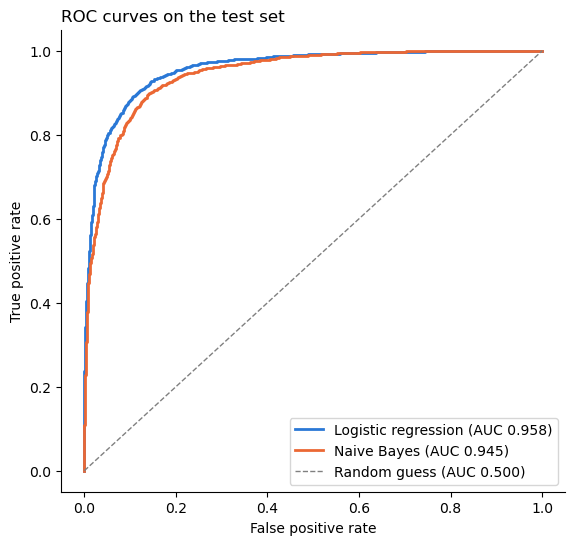

,accuracy,precision,recall,f1,roc_auc
Logistic regression,0.891,0.876,0.908,0.892,0.958
Naive Bayes,0.875,0.873,0.874,0.874,0.945


In [11]:
# ROC curves for both models on the same test set
fpr, tpr, _ = roc_curve(sentiment_test, test_probabilities, pos_label='positive')
nb_fpr, nb_tpr, _ = roc_curve(sentiment_test, nb_test_probabilities, pos_label='positive')
roc_auc, nb_roc_auc = auc(fpr, tpr), auc(nb_fpr, nb_tpr)

fig, ax = plt.subplots(figsize=(6.5, 6))
ax.plot(fpr, tpr, color='#2a78d6', lw=2, label=f'Logistic regression (AUC {roc_auc:.3f})')
ax.plot(nb_fpr, nb_tpr, color='#eb6834', lw=2, label=f'Naive Bayes (AUC {nb_roc_auc:.3f})')
ax.plot([0, 1], [0, 1], color='grey', linestyle='--', lw=1, label='Random guess (AUC 0.500)')
ax.set_xlabel('False positive rate'); ax.set_ylabel('True positive rate')
ax.set_title('ROC curves on the test set', loc='left')
ax.legend(loc='lower right'); ax.spines[['top', 'right']].set_visible(False)
plt.show()

results = pd.DataFrame({
    'accuracy': [accuracy, nb_accuracy], 'precision': [precision, nb_precision],
    'recall': [recall, nb_recall], 'f1': [f1, nb_f1], 'roc_auc': [roc_auc, nb_roc_auc],
}, index=['Logistic regression', 'Naive Bayes'])
results.round(3)

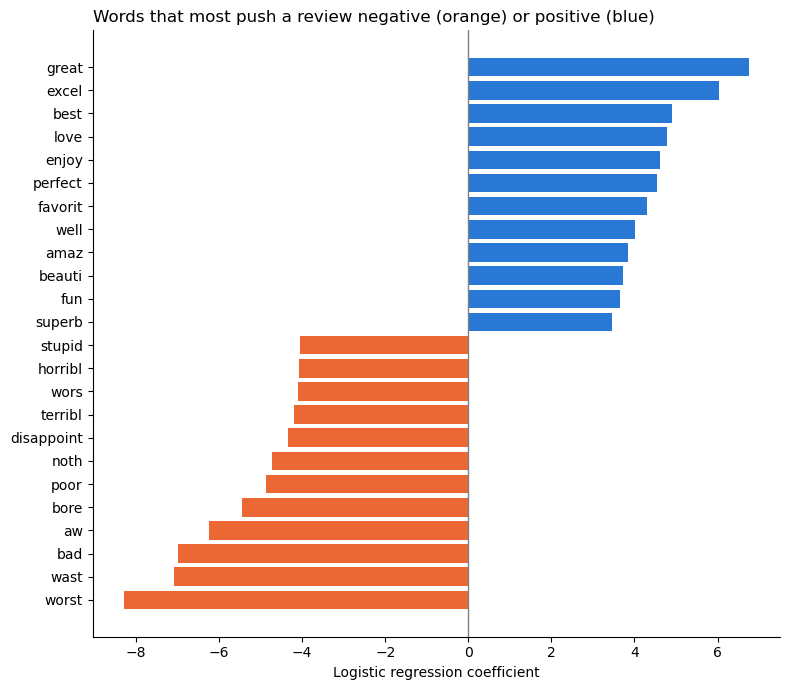

In [12]:
# which stemmed words push the logistic regression toward each class
words = vectorizer.get_feature_names_out()
coefs = model.coef_[0] if model.classes_[1] == 'positive' else -model.coef_[0]
top = pd.Series(coefs, index=words).sort_values()
top_words = pd.concat([top.head(12), top.tail(12)])

fig, ax = plt.subplots(figsize=(8, 7))
ax.barh(top_words.index, top_words.values, color=['#eb6834' if v < 0 else '#2a78d6' for v in top_words.values])
ax.axvline(0, color='grey', lw=1)
ax.set_title('Words that most push a review negative (orange) or positive (blue)', loc='left')
ax.set_xlabel('Logistic regression coefficient')
ax.spines[['top', 'right']].set_visible(False)
plt.tight_layout()
plt.show()

## Findings
- **Training on labeled reviews works far better than prebuilt analyzers.** Logistic regression reaches 89.1% accuracy on 5,000 reviews it never saw, compared with 69.4% for VADER and 68.5% for TextBlob in Part 1.
- **Logistic regression edges out Naive Bayes** on every measure: accuracy 89.1% vs. 87.5%, F1 0.892 vs. 0.874, ROC AUC 0.958 vs. 0.945. It misclassifies 544 of the 5,000 test reviews (318 negative reviews called positive, 226 positive reviews called negative); Naive Bayes misclassifies 624.
- **The model learned sensible signals.** The strongest negative stems include "worst", "wast" (waste), "bad", "aw" (awful), "bore" and "disappoint"; the strongest positive stems include "great", "excel", "best", "love", "enjoy" and "perfect".
- **Limitations and next steps:**
    - NLTK's stop word list removes "not", "no" and "nor", so "not good" becomes "good". Keeping negations, or adding two-word phrases (bigrams), would likely help.
    - Results come from one 80/20 split; cross-validation would give a more reliable estimate.
    - The model has only seen movie reviews and would need retraining for other kinds of text.

**Correction note:** the original Week 5 version replaced the true labels with TextBlob's predictions before training, so its models learned to copy TextBlob rather than real sentiment, and its 0.88 accuracy measured agreement with TextBlob. Its Naive Bayes section also reused the logistic regression predictions, so both models showed identical results. This version trains and scores on the true labels and evaluates each model with its own predictions. The original notebooks are in `earlier_versions/`.